
# C00 — Effective Generation-History Gap Closure

## Scientific question

The observational result is not merely that context utility \(U(k)\) can move under
an intervention. The motivating population-level fact is that machine continuations
have larger long-context utility than matched human text on Ghostbuster and RAID.

C00 asks the mechanistic question:

\[
\boxed{
\text{How much of the human--LLM }U\text{ gap is reproduced by changing only}
}
\]

\[
\boxed{
\text{the generator's effective access to its own previously generated history?}
}
\]

The visible RAID writing task is identical in every condition. The generator,
checkpoint, decoding rule, and maximum generation budget are identical. The
intervention acts during autoregressive generation:

\[
p(x_t\mid P,x_{<t})
\quad\longrightarrow\quad
p(x_t\mid P,x_{t-K:t-1}),
\]

where the intact task prompt \(P\) is always retained and only generated
self-history is capped.

## Frozen source population

We reuse the exact 60 RAID source IDs from the original confirmatory Qwen
self-history intervention:

- 30 news prompts;
- 30 Wikipedia prompts.

The canonical released RAID instruction prompt is recovered for every source.
The matched human \(U\) values come from the frozen RAID feature table used in the
paper.

## Generator and conditions

Primary generator:

- `Qwen/Qwen2.5-1.5B-Instruct`

Greedy decoding in every condition:

\[
K\in\{32,64,128,256,\mathrm{full}\}.
\]

For finite \(K\), every next-token decision is recomputed from

\[
[\text{fixed task prompt};\text{last }K\text{ generated tokens}],
\]

with no generated-history KV cache carried across capped steps. This is the same
intervention semantics used by the previous full-vs-cap32 validation, generalized
to a dose-response sweep.

## Frozen observation model

Primary scorer:

- `Qwen/Qwen3-0.6B-Base`

Frozen RELIC configuration:

- first exactly 384 scorer tokens;
- \(k\in\{8,32,128,256\}\);
- eight fixed target positions from token 256 through token 383;
- \(U(k)=L_8-L_k\).

Define

\[
U_{\rm long}=\frac{U(128)+U(256)}{2}.
\]

## Main estimands

For source \(s\), history condition \(K\), and trace coordinate \(j\),

\[
g_{s,K,j}=U_{s,K,j}-U_{s,H,j}.
\]

The baseline machine-human gap is

\[
g_{\infty,j}=E_s[g_{s,\mathrm{full},j}].
\]

For a finite cap \(K\), scalar gap closure is computed from **ratio of paired
population means**, not unstable document-wise ratios:

\[
C_{K,j}
=
1-
\frac{E_s[g_{s,K,j}]}
     {E_s[g_{s,\mathrm{full},j}]}.
\]

Thus:

- \(C=0\): no gap closure;
- \(0<C<1\): partial closure;
- \(C=1\): mean gap eliminated;
- \(C>1\): overshoot past the human mean;
- \(C<0\): intervention moves farther from humans.

We also treat the three-dimensional context-utility vector

\[
\mathbf U=(U_{32},U_{128},U_{256})
\]

as a trace space. Let

\[
\mathbf g
=
E[\mathbf U_{\rm full}-\mathbf U_H],
\qquad
\boldsymbol\delta_K
=
E[\mathbf U_K-\mathbf U_{\rm full}].
\]

Then

\[
A_K
=
-\frac{\mathbf g^\top\boldsymbol\delta_K}
{\|\mathbf g\|\,\|\boldsymbol\delta_K\|}
\]

measures directional alignment **toward** the human gap, and

\[
P_K
=
-\frac{\mathbf g^\top\boldsymbol\delta_K}
{\|\mathbf g\|^2}
\]

is the fraction of the baseline gap explained along its own direction.

## Predeclared interpretation gate

The primary gap-closure interpretation requires the full-history Qwen baseline to
actually exhibit a positive matched human gap in \(U_{\rm long}\) on this frozen
60-source population, with its paired bootstrap 95% interval above zero.

If that baseline gap is absent, the history intervention can still have a causal
effect, but C00 cannot claim to explain a human--LLM gap that is not present in
this generator/sample.

## Why this is a C-series experiment

The treatment is an inference-time **generation mechanism**, not a prompt-content
manipulation. The final task prompt is held fixed. The causal target is whether
changing effective autoregressive self-history reproduces an already observed
population difference.


In [1]:

from pathlib import Path
import gc
import hashlib
import inspect
import json
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"

OUT = RESULTS / "causal" / "C00_effective_history_gap_closure"
OUT.mkdir(parents=True, exist_ok=True)

GENERATOR_NAME = "Qwen2.5-1.5B-Instruct"
GENERATOR_CHECKPOINT = "Qwen/Qwen2.5-1.5B-Instruct"
SCORER_CHECKPOINT = "Qwen/Qwen3-0.6B-Base"

HISTORY_CAPS = [32, 64, 128, 256]
CONDITIONS = ["K32", "K64", "K128", "K256", "full"]
CAP_BY_CONDITION = {
    "K32": 32,
    "K64": 64,
    "K128": 128,
    "K256": 256,
    "full": None,
}

MAX_NEW_TOKENS = 480

SCORER_PREFIX_LEN = 384
CONTEXTS = [8, 32, 128, 256]
N_TARGETS = 8
TARGET_POSITIONS = np.unique(
    np.linspace(
        max(CONTEXTS),
        SCORER_PREFIX_LEN - 1,
        N_TARGETS,
        dtype=int,
    )
)

N_BOOT = 10_000
BOOT_SEED = 20260902

# Set to a small integer only for debugging. Leave None for the real run.
DEBUG_N = None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True

print("ROOT:", ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("OUT:", OUT)
print("device:", DEVICE)
print("generator:", GENERATOR_CHECKPOINT)
print("scorer:", SCORER_CHECKPOINT)
print("conditions:", CONDITIONS)
print("target positions:", TARGET_POSITIONS)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
PROJECT_ROOT: /home/user/Downloads/TemporalContextResearch
OUT: ../results/causal/C00_effective_history_gap_closure
device: cuda
generator: Qwen/Qwen2.5-1.5B-Instruct
scorer: Qwen/Qwen3-0.6B-Base
conditions: ['K32', 'K64', 'K128', 'K256', 'full']
target positions: [256 274 292 310 328 346 364 383]



## 1. Recover the exact frozen 60 RAID sources

The source IDs are taken from the original Qwen confirmatory self-history
intervention artifact. We then recover the canonical released RAID instruction
prompts exactly as notebook 26 did.

No prompt is reconstructed from a title or generated output.


In [2]:

Q_DIR_CANDIDATES = [
    DATA / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_confirmatory",
]

Q_DIR = next(
    (p for p in Q_DIR_CANDIDATES if (p / "confirmatory_pairs.parquet").exists()),
    None,
)

assert Q_DIR is not None, (
    "Could not locate confirmatory_pairs.parquet. Checked:\n"
    + "\n".join(map(str, Q_DIR_CANDIDATES))
)

frozen_pairs = pd.read_parquet(Q_DIR / "confirmatory_pairs.parquet")
SOURCE_IDS = list(dict.fromkeys(frozen_pairs["source_id"].astype(str)))

assert len(SOURCE_IDS) == 60, f"Expected 60 frozen source IDs, got {len(SOURCE_IDS)}"

if DEBUG_N is not None:
    SOURCE_IDS = SOURCE_IDS[: int(DEBUG_N)]

print("Q_DIR:", Q_DIR)
print("source IDs:", len(SOURCE_IDS))
print("first 5:", SOURCE_IDS[:5])


Q_DIR: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory
source IDs: 60
first 5: ['1b2e45a9-88d5-4983-b735-dc521aa6c1dc', '3b8f603e-fce8-4fb1-b5ef-49015b1e9677', '4e7eee59-305e-4449-a385-516cd0eef09f', 'fc13052b-289e-4247-9444-996c4d420c5d', '914cab2e-a79d-458d-b2c0-b173775dd0dd']


In [3]:

RAID_PROMPT_CANDIDATES = [
    ROOT / "results" / "raid_pilot" / "raid_pilot_wavedetect.parquet",
    DATA / "raid_pilot" / "raid_pilot_wavedetect.parquet",
    PROJECT_ROOT / "data" / "raid_pilot" / "raid_pilot_wavedetect.parquet",
    PROJECT_ROOT / "results" / "raid_pilot" / "raid_pilot_wavedetect.parquet",
]

RAID_PROMPT_SOURCE = next((p for p in RAID_PROMPT_CANDIDATES if p.exists()), None)
assert RAID_PROMPT_SOURCE is not None, (
    "Could not locate raid_pilot_wavedetect.parquet. Checked:\n"
    + "\n".join(map(str, RAID_PROMPT_CANDIDATES))
)

cols = [
    "source_id",
    "prompt",
    "title",
    "domain",
    "model",
    "decoding",
    "repetition_penalty",
    "attack",
]

raid_prompt_rows = pd.read_parquet(
    RAID_PROMPT_SOURCE,
    columns=cols,
).copy()

raid_prompt_rows["source_id"] = raid_prompt_rows["source_id"].astype(str)
raid_prompt_rows = raid_prompt_rows[
    raid_prompt_rows["source_id"].isin(set(SOURCE_IDS))
].copy()

raid_prompt_rows = raid_prompt_rows[
    (raid_prompt_rows["decoding"].astype(str).str.lower() == "greedy")
    & (raid_prompt_rows["repetition_penalty"].astype(str).str.lower() == "no")
    & (raid_prompt_rows["attack"].astype(str).str.lower() == "none")
].copy()

INSTRUCTION_MODELS = {
    "chatgpt",
    "gpt4",
    "llama-chat",
}

inst = raid_prompt_rows[
    raid_prompt_rows["model"].astype(str).str.lower().isin(INSTRUCTION_MODELS)
].copy()

inst = inst[inst["prompt"].notna()].copy()
inst["prompt"] = inst["prompt"].astype(str).str.strip()

prompt_sets = (
    inst.groupby("source_id")["prompt"]
    .agg(lambda s: list(pd.unique(s)))
)

bad = prompt_sets[prompt_sets.map(len) != 1]
assert len(bad) == 0, (
    "RAID instruction-model conditions disagree on the canonical prompt for "
    f"{len(bad)} frozen source IDs."
)

missing = set(SOURCE_IDS) - set(prompt_sets.index)
assert not missing, f"Missing canonical RAID prompts for {len(missing)} source IDs."

prompt_map = {sid: vals[0] for sid, vals in prompt_sets.items()}

meta = (
    inst[["source_id", "title", "domain"]]
    .drop_duplicates()
)
meta_counts = meta.groupby("source_id").size()
assert (meta_counts == 1).all(), "Expected one title/domain pair per source."
meta = meta.set_index("source_id")

prompts = pd.DataFrame({
    "source_id": SOURCE_IDS,
    "prompt": [prompt_map[sid] for sid in SOURCE_IDS],
    "title": [meta.loc[sid, "title"] for sid in SOURCE_IDS],
    "domain": [meta.loc[sid, "domain"] for sid in SOURCE_IDS],
})

prompts["prompt_sha256"] = prompts["prompt"].map(
    lambda x: hashlib.sha256(x.encode("utf-8")).hexdigest()
)

assert len(prompts) == len(SOURCE_IDS)
assert prompts["source_id"].nunique() == len(SOURCE_IDS)
assert prompts["prompt"].str.len().gt(0).all()

prompts.to_parquet(OUT / "frozen_prompts.parquet", index=False)

print("RAID prompt source:", RAID_PROMPT_SOURCE)
display(prompts["domain"].value_counts().rename("n").to_frame())
display(prompts.head())


RAID prompt source: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_wavedetect.parquet


,n
domain,
news,30
wiki,30


,source_id,prompt,title,domain,prompt_sha256
0,1b2e45a9-88d5-4983-b735-dc521aa6c1dc,"Write the body of a BBC news article titled ""A...",Aragones angered by racism fine,news,393ab6341786643a4e0a40e9c09ac40d842dfaad1b2596...
1,3b8f603e-fce8-4fb1-b5ef-49015b1e9677,"Write the body of a BBC news article titled ""M...",Mac Mini heralds mini revolution,news,78c17a8544fc97dc0d3a07a56bbe1ecd599d542272ea3a...
2,4e7eee59-305e-4449-a385-516cd0eef09f,"Write the body of a BBC news article titled ""W...",What's next for next-gen consoles?,news,f26ca2460b4e3f5d80ce37c7915a64d9e69f905ba2b338...
3,fc13052b-289e-4247-9444-996c4d420c5d,"Write the body of a BBC news article titled ""I...",Iraqis win death test case probe,news,7188a004f5016f45d8e1012539d74718c1e69b3d583887...
4,914cab2e-a79d-458d-b2c0-b173775dd0dd,"Write the body of a BBC news article titled ""F...",Format wars could 'confuse users',news,0b6f04ffe817c236ffdb6efa591d41f6b0a7ccae4f2e23...



## 2. Recover matched human context-utility references

The human reference comes from the frozen RAID feature table used in the
observational paper result. This keeps the human side of the comparison fixed
rather than rescoring or resampling it after seeing C00.


In [4]:

RAID_FEATURE_CANDIDATES = [
    DATA / "raid_pilot" / "raid_pilot_frozen_features.parquet",
    PROJECT_ROOT / "data" / "raid_pilot" / "raid_pilot_frozen_features.parquet",
    PROJECT_ROOT / "results" / "raid_pilot" / "raid_pilot_frozen_features.parquet",
]

RAID_FEATURE_PATH = next((p for p in RAID_FEATURE_CANDIDATES if p.exists()), None)
assert RAID_FEATURE_PATH is not None, (
    "Could not locate raid_pilot_frozen_features.parquet. Checked:\n"
    + "\n".join(map(str, RAID_FEATURE_CANDIDATES))
)

raid_features = pd.read_parquet(RAID_FEATURE_PATH).copy()
raid_features["source_id"] = raid_features["source_id"].astype(str)

required = {
    "source_id",
    "domain",
    "model",
    "context_u_32",
    "context_u_128",
    "context_u_256",
}
missing_cols = required - set(raid_features.columns)
assert not missing_cols, f"Missing frozen RAID columns: {sorted(missing_cols)}"

human = (
    raid_features.loc[
        (raid_features["model"] == "human")
        & raid_features["source_id"].isin(set(SOURCE_IDS)),
        [
            "source_id",
            "domain",
            "context_u_32",
            "context_u_128",
            "context_u_256",
        ],
    ]
    .rename(columns={
        "context_u_32": "human_U_32",
        "context_u_128": "human_U_128",
        "context_u_256": "human_U_256",
    })
    .drop_duplicates()
)

assert human["source_id"].nunique() == len(SOURCE_IDS), (
    f"Expected one human reference for every frozen source; got "
    f"{human['source_id'].nunique()}/{len(SOURCE_IDS)}."
)
assert not human["source_id"].duplicated().any()

human["human_U_long"] = (human["human_U_128"] + human["human_U_256"]) / 2

prompt_domain = prompts[["source_id", "domain"]].rename(columns={"domain": "prompt_domain"})
domain_audit = human.merge(prompt_domain, on="source_id", validate="one_to_one")
assert (domain_audit["domain"] == domain_audit["prompt_domain"]).all()

human.to_parquet(OUT / "frozen_human_reference.parquet", index=False)

print("RAID frozen feature source:", RAID_FEATURE_PATH)
display(
    human[["human_U_32", "human_U_128", "human_U_256", "human_U_long"]]
    .describe()
    .T
)


RAID frozen feature source: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_frozen_features.parquet


,count,mean,std,min,25%,50%,75%,max
human_U_32,60.0,0.883742,0.634495,-0.645736,0.484132,0.817706,1.161748,2.839369
human_U_128,60.0,1.288979,0.686591,-0.064940,0.939975,1.277857,1.619759,3.053726
human_U_256,60.0,1.396334,0.666021,0.271581,0.909532,1.403942,1.744432,3.277140
human_U_long,60.0,1.342657,0.669687,0.269441,0.970619,1.302105,1.684115,3.165433



## 3. Generation implementation

For `full`, use ordinary greedy generation.

For a finite cap \(K\), every next-token decision is computed from exactly:

\[
[\text{canonical chat-formatted task prompt};\text{last }K\text{ generated tokens}],
\]

with `use_cache=False`.

This deliberately matches the already-validated self-history intervention
semantics rather than introducing a new KV-pruning implementation in C00.

The prompt token IDs are constant across all conditions for a source.


In [5]:

def normalize_eos_ids(tok, model):
    ids = []
    for obj in [tok, getattr(model, "generation_config", None), model.config]:
        if obj is None:
            continue
        x = getattr(obj, "eos_token_id", None)
        if x is None:
            continue
        if isinstance(x, (list, tuple, set)):
            ids.extend(int(v) for v in x if v is not None)
        else:
            ids.append(int(x))
    return sorted(set(ids))


def supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False


def load_generator(checkpoint):
    tok = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)

    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    kwargs = dict(low_cpu_mem_usage=True)

    try:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            attn_implementation="sdpa",
            **kwargs,
        )
    except Exception:
        try:
            model = AutoModelForCausalLM.from_pretrained(
                checkpoint,
                dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
                **kwargs,
            )
        except TypeError:
            model = AutoModelForCausalLM.from_pretrained(
                checkpoint,
                torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
                **kwargs,
            )

    model.to(DEVICE).eval()
    return tok, model


def build_prompt_ids(tok, prompt):
    messages = [{"role": "user", "content": str(prompt)}]

    encoded = tok.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
    )

    if isinstance(encoded, torch.Tensor):
        ids = encoded
    elif hasattr(encoded, "input_ids"):
        ids = encoded.input_ids
    else:
        ids = encoded["input_ids"]

    if ids.ndim == 1:
        ids = ids.unsqueeze(0)

    assert ids.ndim == 2 and ids.shape[0] == 1
    return ids.to(DEVICE)


@torch.inference_mode()
def generate_full(tok, model, prompt, max_new_tokens=MAX_NEW_TOKENS):
    prompt_ids = build_prompt_ids(tok, prompt)
    input_len = prompt_ids.shape[1]
    eos_ids = normalize_eos_ids(tok, model)

    kwargs = dict(
        input_ids=prompt_ids,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        use_cache=True,
        repetition_penalty=1.0,
        pad_token_id=tok.pad_token_id,
    )

    if eos_ids:
        kwargs["eos_token_id"] = eos_ids if len(eos_ids) > 1 else eos_ids[0]

    output = model.generate(**kwargs)
    new_ids = output[0, input_len:].detach().cpu().tolist()

    return {
        "generated_text": tok.decode(
            new_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        ),
        "generated_token_ids_json": json.dumps(new_ids),
        "n_generator_tokens": len(new_ids),
        "ended_eos": bool(new_ids and new_ids[-1] in set(eos_ids)),
        "prompt_tokens": int(input_len),
        "n_truncating_steps": 0,
        "max_visible_generated_history": max(0, len(new_ids) - 1),
    }


@torch.inference_mode()
def generate_capped(tok, model, prompt, history_cap, max_new_tokens=MAX_NEW_TOKENS):
    assert isinstance(history_cap, int) and history_cap >= 1

    base_prompt = build_prompt_ids(tok, prompt)[0].detach().cpu().tolist()

    generated = []
    eos_ids = set(normalize_eos_ids(tok, model))
    keep_last_only = supports_logits_to_keep(model)

    n_truncating_steps = 0
    max_visible_generated_history = 0

    for _ in range(max_new_tokens):
        if len(generated) > history_cap:
            n_truncating_steps += 1

        suffix = generated[-history_cap:]
        max_visible_generated_history = max(
            max_visible_generated_history,
            len(suffix),
        )

        ids = torch.tensor(
            base_prompt + suffix,
            dtype=torch.long,
            device=DEVICE,
        ).unsqueeze(0)

        kwargs = {
            "input_ids": ids,
            "use_cache": False,
        }
        if keep_last_only:
            kwargs["logits_to_keep"] = 1

        out = model(**kwargs)
        next_id = int(out.logits[:, -1, :].argmax(dim=-1).item())
        generated.append(next_id)

        del ids, out

        if next_id in eos_ids:
            break

    return {
        "generated_text": tok.decode(
            generated,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        ),
        "generated_token_ids_json": json.dumps(generated),
        "n_generator_tokens": len(generated),
        "ended_eos": bool(generated and generated[-1] in eos_ids),
        "prompt_tokens": len(base_prompt),
        "n_truncating_steps": n_truncating_steps,
        "max_visible_generated_history": max_visible_generated_history,
    }



## 4. Implementation preflight

Before the real sweep, verify a property that should hold exactly:

If the finite cap is much larger than the entire generated continuation, the
no-cache capped implementation conditions on the **same token sequence** as
ordinary full-history greedy generation. Therefore the first 64 generated token
IDs must be identical.

This is a code-path validation, not a scientific result.


In [6]:
# Memory-safe implementation preflight.
#
# This validates the generation code path only. It does not need a real RAID prompt
# or a long continuation, so keep the test deliberately tiny on 8 GB GPUs.

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

gen_tok, gen_model = load_generator(GENERATOR_CHECKPOINT)

test_prompt = "Write one short sentence about rain."

full_test = generate_full(
    gen_tok,
    gen_model,
    test_prompt,
    max_new_tokens=8,
)

large_cap_test = generate_capped(
    gen_tok,
    gen_model,
    test_prompt,
    history_cap=1024,
    max_new_tokens=8,
)

full_ids = json.loads(full_test["generated_token_ids_json"])
large_ids = json.loads(large_cap_test["generated_token_ids_json"])

assert full_ids == large_ids, (
    "Implementation preflight failed: a non-binding history cap does not reproduce "
    "ordinary greedy generation exactly."
)

print("PASS: non-binding capped generation exactly matches full greedy generation.")
print("test tokens:", len(full_ids))

if torch.cuda.is_available():
    peak_gb = torch.cuda.max_memory_allocated() / (1024**3)
    print(f"preflight peak allocated GPU memory: {peak_gb:.2f} GiB")

# Keep the generator loaded for the real generation sweep, but release any transient
# tensors/caches created by the preflight.
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 1131.73it/s]


PASS: non-binding capped generation exactly matches full greedy generation.
test tokens: 8
preflight peak allocated GPU memory: 2.89 GiB



## 5. Generate the matched history-range sweep

The output file is checkpointed after each source-condition result. Rerunning the
cell resumes automatically.

The experiment is deterministic. No condition-specific prompt text is introduced.


In [7]:

GEN_PATH = OUT / "generations.parquet"

if GEN_PATH.exists():
    existing = pd.read_parquet(GEN_PATH)
else:
    existing = pd.DataFrame()

if len(existing):
    done = set(zip(existing["source_id"].astype(str), existing["condition"].astype(str)))
    rows = existing.to_dict("records")
else:
    done = set()
    rows = []

total_needed = len(prompts) * len(CONDITIONS)
print(f"resume: {len(done)}/{total_needed} source-condition generations complete")

for _, p in tqdm(
    prompts.iterrows(),
    total=len(prompts),
    desc="C00 history sweep",
):
    source_id = str(p["source_id"])
    prompt = str(p["prompt"])
    prompt_hash = hashlib.sha256(prompt.encode("utf-8")).hexdigest()

    for condition in CONDITIONS:
        key = (source_id, condition)
        if key in done:
            continue

        cap = CAP_BY_CONDITION[condition]
        t0 = time.time()

        if cap is None:
            result = generate_full(
                gen_tok,
                gen_model,
                prompt,
                max_new_tokens=MAX_NEW_TOKENS,
            )
        else:
            result = generate_capped(
                gen_tok,
                gen_model,
                prompt,
                history_cap=cap,
                max_new_tokens=MAX_NEW_TOKENS,
            )

        rows.append({
            "source_id": source_id,
            "domain": p["domain"],
            "title": p["title"],
            "generator": GENERATOR_NAME,
            "generator_checkpoint": GENERATOR_CHECKPOINT,
            "condition": condition,
            "history_cap": np.nan if cap is None else int(cap),
            "prompt_sha256": prompt_hash,
            "seconds": time.time() - t0,
            **result,
        })

        pd.DataFrame(rows).to_parquet(GEN_PATH, index=False)
        done.add(key)

generations = pd.read_parquet(GEN_PATH)

assert len(generations) == total_needed
assert not generations.duplicated(["source_id", "condition"]).any()
assert set(generations["condition"]) == set(CONDITIONS)

print("saved:", GEN_PATH)
print("shape:", generations.shape)


resume: 0/300 source-condition generations complete


C00 history sweep: 100%|████████████████████████████████████████████████████████████████████████████████| 60/60 [56:10<00:00, 56.18s/it]

saved: ../results/causal/C00_effective_history_gap_closure/generations.parquet
shape: (300, 16)



## 6. Mechanism and generation audit

Unlike the abandoned prompt-compliance experiments, the mechanism here is directly
implemented by the generation algorithm. We nevertheless verify:

1. the prompt hash is identical across all five conditions within source;
2. every finite condition never exposes more than its declared number of generated
   history tokens;
3. finite conditions actually enter the truncating regime on sufficiently long
   continuations;
4. stopping and length changes are reported because they can induce post-treatment
   scorer eligibility.


In [8]:

prompt_hash_counts = generations.groupby("source_id")["prompt_sha256"].nunique()
assert (prompt_hash_counts == 1).all(), "Prompt changed across history conditions."

for condition, cap in CAP_BY_CONDITION.items():
    if cap is None:
        continue

    sub = generations[generations["condition"] == condition]

    assert (sub["max_visible_generated_history"] <= cap).all(), (
        f"{condition} exposed more generated history than its declared cap."
    )

audit = (
    generations.groupby("condition")
    .agg(
        n=("source_id", "size"),
        mean_generator_tokens=("n_generator_tokens", "mean"),
        median_generator_tokens=("n_generator_tokens", "median"),
        eos_fraction=("ended_eos", "mean"),
        hit_max_fraction=(
            "n_generator_tokens",
            lambda x: np.mean(np.asarray(x) >= MAX_NEW_TOKENS),
        ),
        mean_truncating_steps=("n_truncating_steps", "mean"),
        mean_seconds=("seconds", "mean"),
    )
    .reindex(CONDITIONS)
)

display(audit)

finite = generations[generations["condition"] != "full"].copy()
finite["cap"] = finite["condition"].map(CAP_BY_CONDITION)

long_enough = finite["n_generator_tokens"] > finite["cap"]
assert (
    finite.loc[long_enough, "n_truncating_steps"] > 0
).all(), "A finite-cap continuation exceeded K without entering the truncating regime."

print("PASS: mechanism audit.")


,n,mean_generator_tokens,median_generator_tokens,eos_fraction,hit_max_fraction,mean_truncating_steps,mean_seconds
condition,,,,,,,
K32,60,440.100000,480.0,0.116667,0.883333,408.433333,11.097067
K64,60,390.250000,480.0,0.316667,0.683333,328.716667,10.483441
K128,60,378.883333,480.0,0.466667,0.533333,257.800000,12.978396
K256,60,345.316667,356.0,0.750000,0.250000,113.650000,14.849361
full,60,352.816667,359.5,0.716667,0.283333,0.000000,6.745630


PASS: mechanism audit.


In [9]:

# Free generator memory before loading the frozen scorer.
del gen_model
del gen_tok
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()



## 7. Frozen context-utility scorer

This is the strict 384-token implementation used in the modern-generator history
intervention notebooks: a continuation is eligible only if its scorer-tokenized
text reaches all 384 prefix tokens.

Eligibility is measured separately for every condition and is therefore
post-treatment. C00 reports both:

- a **common-eligible** trajectory using the same source IDs for all history caps;
- pairwise full-vs-cap sensitivity analyses.

The common-eligible analysis is the primary dose-response comparison.


In [10]:

def scorer_supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False


def load_scorer(checkpoint):
    tok = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)

    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    try:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(
            checkpoint,
            torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )

    model.to(DEVICE).eval()
    return tok, model


def encode_prefix(tok, text):
    return tok(
        str(text),
        add_special_tokens=False,
        truncation=False,
    )["input_ids"][:SCORER_PREFIX_LEN]


@torch.inference_mode()
def score_context_utility(model, ids):
    assert len(ids) == SCORER_PREFIX_LEN

    keep = scorer_supports_logits_to_keep(model)
    losses = {k: [] for k in CONTEXTS}

    for k in CONTEXTS:
        seqs = []
        target_ids = []

        for t in TARGET_POSITIONS:
            seqs.append(torch.tensor(ids[t-k:t], dtype=torch.long))
            target_ids.append(int(ids[t]))

        batch = torch.stack(seqs, dim=0).to(DEVICE)
        targets = torch.tensor(
            target_ids,
            dtype=torch.long,
            device=DEVICE,
        )

        kwargs = {
            "input_ids": batch,
            "use_cache": False,
        }
        if keep:
            kwargs["logits_to_keep"] = 1

        out = model(**kwargs)
        logits = out.logits[:, -1, :].float()
        logp = torch.log_softmax(logits, dim=-1)
        nll = -logp.gather(1, targets[:, None]).squeeze(1)

        losses[k] = nll.detach().cpu().numpy().astype(float)

        del batch, targets, out, logits, logp, nll

    result = {
        f"L_{k}": float(np.mean(losses[k]))
        for k in CONTEXTS
    }

    for k in [32, 128, 256]:
        result[f"U_{k}"] = result["L_8"] - result[f"L_{k}"]

    result["U_long"] = (result["U_128"] + result["U_256"]) / 2
    return result


In [11]:

score_tok, score_model = load_scorer(SCORER_CHECKPOINT)

SCORE_PATH = OUT / "context_scores.parquet"

if SCORE_PATH.exists():
    existing_scores = pd.read_parquet(SCORE_PATH)
else:
    existing_scores = pd.DataFrame()

if len(existing_scores):
    scored_done = set(
        zip(
            existing_scores["source_id"].astype(str),
            existing_scores["condition"].astype(str),
        )
    )
    score_rows = existing_scores.to_dict("records")
else:
    scored_done = set()
    score_rows = []

for _, row in tqdm(
    generations.iterrows(),
    total=len(generations),
    desc="C00 U scoring",
):
    key = (str(row["source_id"]), str(row["condition"]))
    if key in scored_done:
        continue

    ids = encode_prefix(score_tok, row["generated_text"])
    eligible = len(ids) == SCORER_PREFIX_LEN

    result = {
        "source_id": str(row["source_id"]),
        "condition": str(row["condition"]),
        "scorer_checkpoint": SCORER_CHECKPOINT,
        "scorer_tokens_capped": len(ids),
        "eligible_U": bool(eligible),
    }

    if eligible:
        result.update(score_context_utility(score_model, ids))
    else:
        for k in CONTEXTS:
            result[f"L_{k}"] = np.nan
        for k in [32, 128, 256]:
            result[f"U_{k}"] = np.nan
        result["U_long"] = np.nan

    score_rows.append(result)
    pd.DataFrame(score_rows).to_parquet(SCORE_PATH, index=False)
    scored_done.add(key)

scores = pd.read_parquet(SCORE_PATH)

assert len(scores) == len(generations)
assert not scores.duplicated(["source_id", "condition"]).any()

print("saved:", SCORE_PATH)
display(
    scores.groupby("condition")["eligible_U"]
    .agg(["sum", "count", "mean"])
    .reindex(CONDITIONS)
    .rename(columns={"sum": "eligible", "mean": "eligible_fraction"})
)


C00 U scoring: 100%|██████████████████████████████████████████████████████████████████████████████████| 300/300 [00:46<00:00,  6.48it/s]

saved: ../results/causal/C00_effective_history_gap_closure/context_scores.parquet


,eligible,count,eligible_fraction
condition,,,
K32,54,60,0.900000
K64,44,60,0.733333
K128,37,60,0.616667
K256,25,60,0.416667
full,27,60,0.450000


In [12]:

del score_model
del score_tok
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()



## 8. Construct the common matched analysis population

Human references are pre-existing and unaffected by treatment.

For the primary trajectory, a source is included only if:

- its human \(U_{32},U_{128},U_{256}\) are finite;
- all five Qwen history conditions are scorer-eligible.

This gives one fixed source set for the entire history-range curve.

Because generation length is treatment-affected, this common eligibility is still a
post-treatment selection event. The notebook therefore also reports pairwise
eligibility and later saves pairwise sensitivity estimates.


In [13]:

analysis = (
    scores
    .merge(
        generations[
            [
                "source_id",
                "condition",
                "domain",
                "n_generator_tokens",
                "ended_eos",
                "n_truncating_steps",
            ]
        ],
        on=["source_id", "condition"],
        validate="one_to_one",
    )
    .merge(
        human,
        on=["source_id", "domain"],
        how="left",
        validate="many_to_one",
    )
)

for k in [32, 128, 256]:
    analysis[f"gap_U_{k}"] = analysis[f"U_{k}"] - analysis[f"human_U_{k}"]

analysis["gap_U_long"] = analysis["U_long"] - analysis["human_U_long"]

human_finite_ids = set(
    human.loc[
        human[
            ["human_U_32", "human_U_128", "human_U_256", "human_U_long"]
        ].notna().all(axis=1),
        "source_id",
    ].astype(str)
)

elig_wide = (
    scores.pivot(
        index="source_id",
        columns="condition",
        values="eligible_U",
    )
    .reindex(columns=CONDITIONS)
)

common_ids = set(
    elig_wide.index[
        elig_wide.fillna(False).all(axis=1)
    ].astype(str)
) & human_finite_ids

COMMON_N = len(common_ids)

print("total frozen sources:", len(SOURCE_IDS))
print("human-finite sources:", len(human_finite_ids))
print("common all-condition eligible:", COMMON_N)

pairwise_rows = []
for condition in CONDITIONS[:-1]:
    sub = elig_wide[[condition, "full"]].fillna(False).all(axis=1)
    ids = set(elig_wide.index[sub].astype(str)) & human_finite_ids
    pairwise_rows.append({
        "condition": condition,
        "pairwise_full_cap_human_n": len(ids),
    })

pairwise_eligibility = pd.DataFrame(pairwise_rows)
display(pairwise_eligibility)

analysis["common_eligible"] = analysis["source_id"].astype(str).isin(common_ids)
analysis.to_parquet(OUT / "analysis_long.parquet", index=False)

if COMMON_N < int(0.75 * len(SOURCE_IDS)):
    print(
        "WARNING: common eligibility is below 75% of the frozen source population. "
        "Treat dose-response estimates as materially selected."
    )


total frozen sources: 60
human-finite sources: 60
common all-condition eligible: 15


,condition,pairwise_full_cap_human_n
0,K32,26
1,K64,22
2,K128,23
3,K256,23



## 9. Baseline human-gap gate

Before asking whether history restriction closes the human--LLM gap, establish that
the full-history generator actually has the expected positive gap on this exact
sample.

Primary gate:

\[
E[U_{\rm long}^{\rm full}-U_{\rm long}^{H}]>0
\]

with paired bootstrap 95% CI entirely above zero.


In [14]:

def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=BOOT_SEED):
    x = pd.Series(values).dropna().to_numpy(float)
    assert len(x) > 0

    rr = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for b in range(n_boot):
        ix = rr.integers(0, len(x), len(x))
        boot[b] = x[ix].mean()

    lo, hi = np.quantile(boot, [0.025, 0.975])

    return {
        "n": len(x),
        "mean": float(x.mean()),
        "ci_low": float(lo),
        "ci_high": float(hi),
    }


common = analysis[analysis["common_eligible"]].copy()

full_common = common[common["condition"] == "full"].copy()
assert len(full_common) == COMMON_N

baseline_rows = []

for metric in ["gap_U_32", "gap_U_128", "gap_U_256", "gap_U_long"]:
    baseline_rows.append({
        "metric": metric,
        **bootstrap_mean_ci(
            full_common[metric],
            seed=BOOT_SEED + len(baseline_rows),
        ),
    })

baseline_gap = pd.DataFrame(baseline_rows)
display(baseline_gap)

primary = baseline_gap[baseline_gap["metric"] == "gap_U_long"].iloc[0]
FULL_GAP_PRESENT = bool(primary["ci_low"] > 0)

print("FULL_GAP_PRESENT =", FULL_GAP_PRESENT)

baseline_gap.to_csv(OUT / "baseline_full_vs_human_gap.csv", index=False)

if not FULL_GAP_PRESENT:
    print(
        "STOP INTERPRETATION GATE: the full-history generator does not show a "
        "resolved positive U_long human gap on this common sample. "
        "Do not describe later ratios as human-gap closure."
    )


,metric,n,mean,ci_low,ci_high
0,gap_U_32,15,0.442501,-0.038356,0.944467
1,gap_U_128,15,1.087126,0.484979,1.722111
2,gap_U_256,15,1.201451,0.599732,1.802128
3,gap_U_long,15,1.144288,0.537856,1.746716


FULL_GAP_PRESENT = True



## 10. Human-relative history trajectory

First inspect the directly interpretable quantity:

\[
E[U_K-U_H]
\]

for every cap. If effective history explains the observed human--LLM signature,
the human-relative gap should contract as the generator's accessible self-history
shrinks.


In [15]:

trajectory_rows = []

for condition in CONDITIONS:
    block = common[common["condition"] == condition]

    for metric in ["gap_U_32", "gap_U_128", "gap_U_256", "gap_U_long"]:
        trajectory_rows.append({
            "condition": condition,
            "history_cap": CAP_BY_CONDITION[condition],
            "metric": metric,
            **bootstrap_mean_ci(
                block[metric],
                seed=BOOT_SEED
                + 100 * CONDITIONS.index(condition)
                + ["gap_U_32", "gap_U_128", "gap_U_256", "gap_U_long"].index(metric),
            ),
        })

trajectory = pd.DataFrame(trajectory_rows)
display(
    trajectory.pivot(
        index="condition",
        columns="metric",
        values="mean",
    ).reindex(CONDITIONS)
)

trajectory.to_csv(OUT / "human_gap_trajectory.csv", index=False)


metric,gap_U_128,gap_U_256,gap_U_32,gap_U_long
condition,,,,
K32,0.363133,0.418248,0.158004,0.390691
K64,0.568816,0.541786,0.006167,0.555301
K128,1.201770,1.119780,0.135003,1.160775
K256,0.837887,0.993971,0.322811,0.915929
full,1.087126,1.201451,0.442501,1.144288



## 11. Scalar gap-closure estimates

The bootstrap resamples source IDs jointly and recomputes both the full-history
and capped human-relative means in each replicate.

This preserves the paired structure and estimates uncertainty in the ratio of
population means:

\[
C_{K,j}
=
1-\frac{\bar g_{K,j}}{\bar g_{\infty,j}}.
\]


In [16]:

def bootstrap_gap_closure(
    wide,
    human_col,
    full_col,
    cap_col,
    n_boot=N_BOOT,
    seed=BOOT_SEED,
):
    z = wide[[human_col, full_col, cap_col]].dropna()
    h = z[human_col].to_numpy(float)
    f = z[full_col].to_numpy(float)
    c = z[cap_col].to_numpy(float)

    full_gap = f - h
    cap_gap = c - h
    shift = c - f

    denom = full_gap.mean()
    assert abs(denom) > 1e-10

    estimate = {
        "n": len(z),
        "full_gap": float(full_gap.mean()),
        "cap_gap": float(cap_gap.mean()),
        "cap_minus_full": float(shift.mean()),
        "closure": float(1 - cap_gap.mean() / denom),
    }

    rr = np.random.default_rng(seed)
    boot = np.empty((n_boot, 4), dtype=float)

    for b in range(n_boot):
        ix = rr.integers(0, len(z), len(z))
        fg = full_gap[ix].mean()
        cg = cap_gap[ix].mean()
        sh = shift[ix].mean()

        boot[b] = [
            fg,
            cg,
            sh,
            1 - cg / fg if abs(fg) > 1e-10 else np.nan,
        ]

    labels = ["full_gap", "cap_gap", "cap_minus_full", "closure"]

    for j, label in enumerate(labels):
        vals = boot[:, j]
        vals = vals[np.isfinite(vals)]
        estimate[f"{label}_ci_low"] = float(np.quantile(vals, 0.025))
        estimate[f"{label}_ci_high"] = float(np.quantile(vals, 0.975))

    return estimate


metric_map = {
    "U_32": ("human_U_32", "U_32"),
    "U_128": ("human_U_128", "U_128"),
    "U_256": ("human_U_256", "U_256"),
    "U_long": ("human_U_long", "U_long"),
}

closure_rows = []

for metric, (human_col, value_col) in metric_map.items():
    wide = (
        common.pivot(
            index="source_id",
            columns="condition",
            values=value_col,
        )
        .reindex(columns=CONDITIONS)
    )
    human_map = (
        human.set_index("source_id")[human_col]
        .reindex(wide.index)
    )
    wide = wide.copy()
    wide["human"] = human_map

    for condition in CONDITIONS[:-1]:
        est = bootstrap_gap_closure(
            wide,
            human_col="human",
            full_col="full",
            cap_col=condition,
            seed=BOOT_SEED
            + 1000 * list(metric_map).index(metric)
            + CONDITIONS.index(condition),
        )

        closure_rows.append({
            "metric": metric,
            "condition": condition,
            "history_cap": CAP_BY_CONDITION[condition],
            **est,
        })

closure = pd.DataFrame(closure_rows)

display(
    closure[
        [
            "metric",
            "condition",
            "n",
            "full_gap",
            "cap_gap",
            "cap_minus_full",
            "closure",
            "closure_ci_low",
            "closure_ci_high",
        ]
    ]
)

closure.to_csv(OUT / "gap_closure_scalar.csv", index=False)


,metric,condition,n,full_gap,cap_gap,cap_minus_full,closure,closure_ci_low,closure_ci_high
0,U_32,K32,15,0.442501,0.158004,-0.284497,0.642930,-1.116501,2.299060
1,U_32,K64,15,0.442501,0.006167,-0.436334,0.986064,-1.743679,3.556281
2,U_32,K128,15,0.442501,0.135003,-0.307498,0.694909,-1.812586,3.310295
3,U_32,K256,15,0.442501,0.322811,-0.119690,0.270485,-1.241132,1.414950
4,U_128,K32,15,1.087126,0.363133,-0.723993,0.665970,0.304845,1.186934
5,U_128,K64,15,1.087126,0.568816,-0.518310,0.476771,-0.530248,1.027778
6,U_128,K128,15,1.087126,1.201770,0.114644,-0.105456,-1.026598,0.331684
7,U_128,K256,15,1.087126,0.837887,-0.249238,0.229264,-0.135036,0.530702
8,U_256,K32,15,1.201451,0.418248,-0.783203,0.651881,0.360257,1.040040
9,U_256,K64,15,1.201451,0.541786,-0.659665,0.549057,-0.295914,1.009141



## 12. Vector alignment with the observed human gap

A mechanism can strongly move the trace without explaining the real population
difference. We therefore compare its displacement directly with the baseline
three-coordinate human gap.

For each cap, report:

- **toward-human cosine** \(A_K\);
- **projection closure** \(P_K\);
- **residual gap ratio**
  \[
  R_K=\frac{\|\mathbf g+\boldsymbol\delta_K\|}{\|\mathbf g\|}.
  \]

A useful explanatory mechanism should have:

\[
A_K>0,\qquad P_K>0,\qquad R_K<1.
\]


In [17]:

U_COLS = ["U_32", "U_128", "U_256"]
HUMAN_U_COLS = ["human_U_32", "human_U_128", "human_U_256"]

common_source_order = sorted(common_ids)

gen_wide = {
    condition: (
        common[common["condition"] == condition]
        .set_index("source_id")
        .reindex(common_source_order)[U_COLS]
        .to_numpy(float)
    )
    for condition in CONDITIONS
}

human_matrix = (
    human.set_index("source_id")
    .reindex(common_source_order)[HUMAN_U_COLS]
    .to_numpy(float)
)

def vector_stats(h, full, cap):
    g = np.mean(full - h, axis=0)
    delta = np.mean(cap - full, axis=0)

    g_norm = np.linalg.norm(g)
    d_norm = np.linalg.norm(delta)

    toward_cos = (
        -float(np.dot(g, delta) / (g_norm * d_norm))
        if g_norm > 0 and d_norm > 0
        else np.nan
    )

    projection_closure = (
        -float(np.dot(g, delta) / (g_norm ** 2))
        if g_norm > 0
        else np.nan
    )

    residual_ratio = (
        float(np.linalg.norm(g + delta) / g_norm)
        if g_norm > 0
        else np.nan
    )

    return {
        "gap_norm": float(g_norm),
        "shift_norm": float(d_norm),
        "toward_human_cosine": toward_cos,
        "projection_closure": projection_closure,
        "residual_gap_ratio": residual_ratio,
    }


def bootstrap_vector_stats(h, full, cap, n_boot=N_BOOT, seed=BOOT_SEED):
    estimate = vector_stats(h, full, cap)

    rr = np.random.default_rng(seed)
    keys = [
        "gap_norm",
        "shift_norm",
        "toward_human_cosine",
        "projection_closure",
        "residual_gap_ratio",
    ]
    boots = {k: [] for k in keys}

    for _ in range(n_boot):
        ix = rr.integers(0, len(h), len(h))
        s = vector_stats(h[ix], full[ix], cap[ix])
        for k in keys:
            if np.isfinite(s[k]):
                boots[k].append(s[k])

    for k in keys:
        vals = np.asarray(boots[k], dtype=float)
        estimate[f"{k}_ci_low"] = float(np.quantile(vals, 0.025))
        estimate[f"{k}_ci_high"] = float(np.quantile(vals, 0.975))

    return estimate


vector_rows = []

for condition in CONDITIONS[:-1]:
    vector_rows.append({
        "condition": condition,
        "history_cap": CAP_BY_CONDITION[condition],
        **bootstrap_vector_stats(
            human_matrix,
            gen_wide["full"],
            gen_wide[condition],
            seed=BOOT_SEED + CONDITIONS.index(condition),
        ),
    })

vector_results = pd.DataFrame(vector_rows)

display(
    vector_results[
        [
            "condition",
            "history_cap",
            "toward_human_cosine",
            "toward_human_cosine_ci_low",
            "toward_human_cosine_ci_high",
            "projection_closure",
            "projection_closure_ci_low",
            "projection_closure_ci_high",
            "residual_gap_ratio",
            "residual_gap_ratio_ci_low",
            "residual_gap_ratio_ci_high",
        ]
    ]
)

vector_results.to_csv(OUT / "gap_closure_vector.csv", index=False)


,condition,history_cap,toward_human_cosine,toward_human_cosine_ci_low,toward_human_cosine_ci_high,projection_closure,projection_closure_ci_low,projection_closure_ci_high,residual_gap_ratio,residual_gap_ratio_ci_low,residual_gap_ratio_ci_high
0,K32,32,0.999930,0.905889,0.999888,0.657162,0.327479,1.103150,0.342927,0.091597,0.699342
1,K64,64,0.975333,-0.836726,0.999197,0.549106,-0.393904,1.059785,0.467707,0.115870,1.432762
2,K128,128,0.192879,-0.976100,0.914386,0.038835,-0.782044,0.480333,0.981259,0.588680,1.810002
3,K256,256,0.987228,-0.847342,0.999308,0.203179,-0.143079,0.473553,0.797496,0.537509,1.151292



## 13. Dose-response test

For the finite caps only,

\[
K\in\{32,64,128,256\},
\]

fit a per-source linear slope of \(U_{\rm long}\) against \(\log_2 K\).

The mechanistic prediction from an effective-history explanation is:

\[
\boxed{
\frac{\partial U_{\rm long}}{\partial \log_2 K}>0.
}
\]

This is not a claim that the relationship must be exactly linear; the slope is a
compact ordered-trend statistic for the predeclared four-point sweep.


In [18]:

finite_conditions = ["K32", "K64", "K128", "K256"]
x = np.log2(np.array([32, 64, 128, 256], dtype=float))

u_long_wide = (
    common.pivot(
        index="source_id",
        columns="condition",
        values="U_long",
    )
    .reindex(columns=finite_conditions)
)

slopes = []

for source_id, row in u_long_wide.iterrows():
    y = row.to_numpy(float)
    assert np.isfinite(y).all()
    slope = np.polyfit(x, y, deg=1)[0]
    slopes.append({
        "source_id": source_id,
        "slope_U_long_per_log2K": float(slope),
    })

slopes = pd.DataFrame(slopes)
slope_summary = bootstrap_mean_ci(
    slopes["slope_U_long_per_log2K"],
    seed=BOOT_SEED + 9000,
)

print("Mean finite-cap U_long slope per doubling of K:")
print(slope_summary)

# A descriptive monotonicity diagnostic, not a significance test.
arr = u_long_wide.to_numpy(float)
monotone_fraction = np.mean(np.all(np.diff(arr, axis=1) >= 0, axis=1))
print("strict nondecreasing source-level trajectory fraction:", monotone_fraction)

slopes.to_csv(OUT / "dose_response_source_slopes.csv", index=False)
pd.DataFrame([{
    **slope_summary,
    "monotone_fraction": float(monotone_fraction),
}]).to_csv(OUT / "dose_response_summary.csv", index=False)


Mean finite-cap U_long slope per doubling of K:
{'n': 15, 'mean': 0.2181189167300356, 'ci_low': 0.10330308421238064, 'ci_high': 0.3403020668877197}
strict nondecreasing source-level trajectory fraction: 0.13333333333333333



## 14. Pairwise-eligibility sensitivity

The common trajectory is the cleanest comparison across \(K\), but it can discard
sources because one *other* cap produced a short continuation.

As a sensitivity check, recompute each cap-vs-full \(U_{\rm long}\) closure using
only the human-finite sources for which that particular pair is 384-token eligible.

Large disagreement between common and pairwise analyses indicates material
post-treatment selection.


In [19]:

pairwise_sensitivity_rows = []

for condition in CONDITIONS[:-1]:
    needed = analysis[
        analysis["condition"].isin([condition, "full"])
    ].copy()

    elig = (
        needed.pivot(
            index="source_id",
            columns="condition",
            values="eligible_U",
        )[[condition, "full"]]
        .fillna(False)
        .all(axis=1)
    )

    ids = set(elig.index[elig].astype(str)) & human_finite_ids

    block = analysis[analysis["source_id"].astype(str).isin(ids)].copy()

    wide = (
        block.pivot(
            index="source_id",
            columns="condition",
            values="U_long",
        )[[condition, "full"]]
    )

    h = (
        human.set_index("source_id")["human_U_long"]
        .reindex(wide.index)
    )
    wide["human"] = h

    est = bootstrap_gap_closure(
        wide,
        human_col="human",
        full_col="full",
        cap_col=condition,
        seed=BOOT_SEED + 12_000 + CONDITIONS.index(condition),
    )

    pairwise_sensitivity_rows.append({
        "condition": condition,
        "history_cap": CAP_BY_CONDITION[condition],
        **est,
    })

pairwise_sensitivity = pd.DataFrame(pairwise_sensitivity_rows)

display(
    pairwise_sensitivity[
        [
            "condition",
            "n",
            "full_gap",
            "cap_gap",
            "cap_minus_full",
            "closure",
            "closure_ci_low",
            "closure_ci_high",
        ]
    ]
)

pairwise_sensitivity.to_csv(
    OUT / "gap_closure_pairwise_eligibility_sensitivity.csv",
    index=False,
)


,condition,n,full_gap,cap_gap,cap_minus_full,closure,closure_ci_low,closure_ci_high
0,K32,26,0.887310,0.380502,-0.506807,0.571173,0.185753,1.037983
1,K64,22,1.172118,0.535167,-0.636952,0.543419,0.010495,0.906058
2,K128,23,0.829973,0.952303,0.122330,-0.147390,-1.185944,0.294847
3,K256,23,0.781117,0.601086,-0.180030,0.230478,-0.102418,0.600458



## 15. Mechanism trajectory figure

The y-axis is the matched human-relative \(U_{\rm long}\) gap. Human equality is
therefore zero.

This figure answers the main C00 question visually: as effective self-history is
reduced, does the model move toward the human trace?


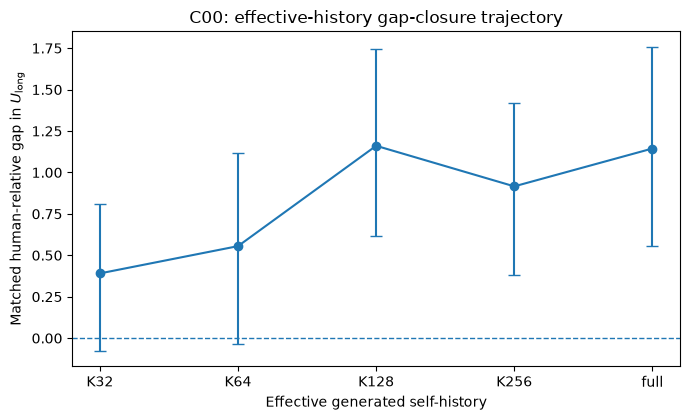

saved: ../results/causal/C00_effective_history_gap_closure/history_gap_closure_trajectory.png


In [20]:

plot = trajectory[trajectory["metric"] == "gap_U_long"].copy()
plot["order"] = plot["condition"].map({c: i for i, c in enumerate(CONDITIONS)})
plot = plot.sort_values("order")

xpos = np.arange(len(plot))
means = plot["mean"].to_numpy(float)
lo = plot["ci_low"].to_numpy(float)
hi = plot["ci_high"].to_numpy(float)

fig, ax = plt.subplots(figsize=(7.0, 4.3))
ax.errorbar(
    xpos,
    means,
    yerr=np.vstack([means - lo, hi - means]),
    marker="o",
    capsize=4,
)
ax.axhline(0.0, linestyle="--", linewidth=1)
ax.set_xticks(xpos)
ax.set_xticklabels(plot["condition"].tolist())
ax.set_xlabel("Effective generated self-history")
ax.set_ylabel(r"Matched human-relative gap in $U_{\rm long}$")
ax.set_title("C00: effective-history gap-closure trajectory")
fig.tight_layout()

FIG_PATH = OUT / "history_gap_closure_trajectory.png"
fig.savefig(FIG_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("saved:", FIG_PATH)


In [21]:
# ============================================================
# Baseline-defined eligibility audit
#
# Define the population using ONLY:
#   1. frozen human reference is finite
#   2. untreated/full-history generation is scorer-eligible
#
# Finite-cap eligibility is NOT used to choose this population.
# ============================================================

full_rows = analysis[
    analysis["condition"].eq("full")
].copy()

BASELINE_IDS = set(
    full_rows.loc[
        full_rows["eligible_U"].fillna(False)
        & full_rows["source_id"].astype(str).isin(human_finite_ids),
        "source_id",
    ].astype(str)
)

BASELINE_N = len(BASELINE_IDS)

print("Baseline-defined population:", BASELINE_N)
assert BASELINE_N > 0


# ------------------------------------------------------------
# Baseline full-history gap using ALL baseline-defined sources.
# This quantity does not change across cap conditions.
# ------------------------------------------------------------

baseline_full = (
    analysis[
        analysis["condition"].eq("full")
        & analysis["source_id"].astype(str).isin(BASELINE_IDS)
    ]
    .copy()
)

assert len(baseline_full) == BASELINE_N

baseline_full_gap = bootstrap_mean_ci(
    baseline_full["gap_U_long"],
    seed=BOOT_SEED + 15000,
)

print("\nFull-history U_long gap on baseline-defined population:")
print(baseline_full_gap)


# ------------------------------------------------------------
# For each intervention:
#
# - How many of the baseline-defined sources remain measurable?
# - Did the intervention alter generation length / stopping?
# - Among measurable outputs, how much U_long gap closes?
# - Does cap eligibility preferentially retain sources with a
#   different PRE-TREATMENT/full-history gap?
# ------------------------------------------------------------

audit_rows = []

for condition in CONDITIONS:

    block = (
        analysis[
            analysis["condition"].eq(condition)
            & analysis["source_id"].astype(str).isin(BASELINE_IDS)
        ]
        .copy()
    )

    assert len(block) == BASELINE_N

    eligible_ids = set(
        block.loc[
            block["eligible_U"].fillna(False),
            "source_id",
        ].astype(str)
    )

    retained_n = len(eligible_ids)
    retention = retained_n / BASELINE_N

    # Generation behavior is observable for all baseline-defined
    # sources whether or not U is scorer-eligible.
    mean_tokens = block["n_generator_tokens"].mean()
    median_tokens = block["n_generator_tokens"].median()
    eos_fraction = block["ended_eos"].mean()
    hit_max_fraction = np.mean(
        block["n_generator_tokens"].to_numpy()
        >= MAX_NEW_TOKENS
    )

    row = {
        "condition": condition,
        "history_cap": CAP_BY_CONDITION[condition],
        "baseline_n": BASELINE_N,
        "eligible_n": retained_n,
        "retention_fraction": retention,
        "mean_generator_tokens": float(mean_tokens),
        "median_generator_tokens": float(median_tokens),
        "eos_fraction": float(eos_fraction),
        "hit_max_fraction": float(hit_max_fraction),
    }

    if condition == "full":
        row.update({
            "full_gap_retained": baseline_full["gap_U_long"].mean(),
            "cap_gap_retained": baseline_full["gap_U_long"].mean(),
            "cap_minus_full": 0.0,
            "closure": 0.0,
            "closure_ci_low": np.nan,
            "closure_ci_high": np.nan,
            "baseline_selection_shift": 0.0,
        })

    elif retained_n > 0:
        # Use exactly the baseline-defined sources that remain
        # measurable under THIS intervention.
        retained = analysis[
            analysis["source_id"].astype(str).isin(eligible_ids)
            & analysis["condition"].isin([condition, "full"])
        ].copy()

        wide = (
            retained.pivot(
                index="source_id",
                columns="condition",
                values="U_long",
            )[[condition, "full"]]
        )

        h = (
            human.set_index("source_id")["human_U_long"]
            .reindex(wide.index)
        )

        wide["human"] = h

        est = bootstrap_gap_closure(
            wide,
            human_col="human",
            full_col="full",
            cap_col=condition,
            seed=BOOT_SEED + 16000 + CONDITIONS.index(condition),
        )

        # Important selection diagnostic:
        #
        # Is the FULL-history gap among sources surviving this
        # intervention different from the full-history gap in the
        # entire baseline-defined population?
        full_gap_retained = est["full_gap"]

        row.update({
            "full_gap_retained": full_gap_retained,
            "cap_gap_retained": est["cap_gap"],
            "cap_minus_full": est["cap_minus_full"],
            "closure": est["closure"],
            "closure_ci_low": est["closure_ci_low"],
            "closure_ci_high": est["closure_ci_high"],
            "baseline_selection_shift": (
                full_gap_retained
                - baseline_full_gap["mean"]
            ),
        })

    audit_rows.append(row)


baseline_defined_audit = pd.DataFrame(audit_rows)

display(
    baseline_defined_audit[
        [
            "condition",
            "baseline_n",
            "eligible_n",
            "retention_fraction",
            "mean_generator_tokens",
            "hit_max_fraction",
            "full_gap_retained",
            "cap_gap_retained",
            "cap_minus_full",
            "closure",
            "closure_ci_low",
            "closure_ci_high",
            "baseline_selection_shift",
        ]
    ]
)

baseline_defined_audit.to_csv(
    OUT / "baseline_defined_eligibility_audit.csv",
    index=False,
)


# ------------------------------------------------------------
# Highlight K32 because this is currently the strongest
# mechanistic result.
# ------------------------------------------------------------

k32 = baseline_defined_audit[
    baseline_defined_audit["condition"].eq("K32")
].iloc[0]

print("\n=== K32 BASELINE-DEFINED AUDIT ===")
print(
    f"retained: {int(k32.eligible_n)}/{int(k32.baseline_n)} "
    f"({k32.retention_fraction:.1%})"
)
print(
    f"full gap among retained sources: "
    f"{k32.full_gap_retained:.6f}"
)
print(
    f"K32 gap among retained sources: "
    f"{k32.cap_gap_retained:.6f}"
)
print(
    f"gap closure: {k32.closure:.3f} "
    f"[{k32.closure_ci_low:.3f}, "
    f"{k32.closure_ci_high:.3f}]"
)
print(
    f"baseline-selection shift: "
    f"{k32.baseline_selection_shift:+.6f}"
)

Baseline-defined population: 27

Full-history U_long gap on baseline-defined population:
{'n': 27, 'mean': 0.848379643673791, 'ci_low': 0.4039795860787368, 'ci_high': 1.2990167251220348}


,condition,baseline_n,eligible_n,retention_fraction,mean_generator_tokens,hit_max_fraction,full_gap_retained,cap_gap_retained,cap_minus_full,closure,closure_ci_low,closure_ci_high,baseline_selection_shift
0,K32,27,26,0.962963,470.111111,0.962963,0.887310,0.380502,-0.506807,0.571173,0.187486,1.034776,0.038930
1,K64,27,22,0.814815,421.481481,0.814815,1.172118,0.535167,-0.636952,0.543419,0.029819,0.907557,0.323739
2,K128,27,23,0.851852,453.444444,0.740741,0.829973,0.952303,0.122330,-0.147390,-1.184931,0.302199,-0.018407
3,K256,27,23,0.851852,443.111111,0.555556,0.781117,0.601086,-0.180030,0.230478,-0.109526,0.605007,-0.067263
4,full,27,27,1.000000,462.925926,0.629630,0.848380,0.848380,0.000000,0.000000,NaN,NaN,0.000000



=== K32 BASELINE-DEFINED AUDIT ===
retained: 26/27 (96.3%)
full gap among retained sources: 0.887310
K32 gap among retained sources: 0.380502
gap closure: 0.571 [0.187, 1.035]
baseline-selection shift: +0.038930


In [22]:
# ============================================================
# C00 quality audit — construct paired full/K32 dataset
# ============================================================

import re
from collections import Counter

QUALITY_CONDITIONS = ["full", "K32"]

qpair = (
    generations[
        generations["condition"].isin(QUALITY_CONDITIONS)
    ]
    .pivot(
        index="source_id",
        columns="condition",
        values="generated_text",
    )
    .reset_index()
    .merge(
        prompts[["source_id", "prompt", "domain", "title"]],
        on="source_id",
        validate="one_to_one",
    )
)

assert len(qpair) == len(SOURCE_IDS)
assert qpair[["full", "K32"]].notna().all().all()


# The exact 26-source population underlying the primary
# baseline-defined K32 gap-closure estimate.
k32_eligible_ids = set(
    analysis.loc[
        analysis["condition"].eq("K32")
        & analysis["source_id"].astype(str).isin(BASELINE_IDS)
        & analysis["eligible_U"].fillna(False),
        "source_id",
    ].astype(str)
)

qpair["in_baseline27"] = qpair["source_id"].astype(str).isin(BASELINE_IDS)
qpair["in_trace26"] = qpair["source_id"].astype(str).isin(k32_eligible_ids)

print("all pairs:", len(qpair))
print("baseline-defined:", qpair["in_baseline27"].sum())
print("trace-analysis pairs:", qpair["in_trace26"].sum())

all pairs: 60
baseline-defined: 27
trace-analysis pairs: 26


In [24]:
# ============================================================
# Objective degeneration diagnostics
# ============================================================

def words(text):
    return re.findall(r"[A-Za-z0-9']+", str(text).lower())


def ngram_repetition_fraction(text, n=4):
    toks = words(text)

    if len(toks) < n:
        return np.nan

    grams = [
        tuple(toks[i:i+n])
        for i in range(len(toks) - n + 1)
    ]

    counts = Counter(grams)

    # Fraction of n-gram positions belonging to n-grams that
    # occur more than once.
    repeated_positions = sum(
        c for c in counts.values()
        if c > 1
    )

    return repeated_positions / len(grams)


def distinct_n(text, n=4):
    toks = words(text)

    if len(toks) < n:
        return np.nan

    grams = [
        tuple(toks[i:i+n])
        for i in range(len(toks) - n + 1)
    ]

    return len(set(grams)) / len(grams)


def max_ngram_count(text, n=4):
    toks = words(text)

    if len(toks) < n:
        return np.nan

    counts = Counter(
        tuple(toks[i:i+n])
        for i in range(len(toks) - n + 1)
    )

    return max(counts.values())


objective_rows = []

for _, r in qpair.iterrows():
    for condition in QUALITY_CONDITIONS:
        text = r[condition]

        objective_rows.append({
            "source_id": r["source_id"],
            "condition": condition,
            "word_count": len(words(text)),
            "repeat4_fraction": ngram_repetition_fraction(text, 4),
            "distinct4": distinct_n(text, 4),
            "max_repeat4": max_ngram_count(text, 4),
            "in_baseline27": r["in_baseline27"],
            "in_trace26": r["in_trace26"],
        })

objective = pd.DataFrame(objective_rows)


def paired_objective_summary(df, metric):
    w = (
        df.pivot(
            index="source_id",
            columns="condition",
            values=metric,
        )[["K32", "full"]]
        .dropna()
    )

    d = w["K32"] - w["full"]

    return {
        "metric": metric,
        "n": len(d),
        "K32_mean": w["K32"].mean(),
        "full_mean": w["full"].mean(),
        "delta_K32_minus_full": d.mean(),
    }


for label, mask in [
    ("all60", np.ones(len(objective), dtype=bool)),
    ("baseline27", objective["in_baseline27"]),
    ("trace26", objective["in_trace26"]),
]:
    print("\n===", label, "===")

    display(pd.DataFrame([
        paired_objective_summary(
            objective[mask],
            metric,
        )
        for metric in [
            "word_count",
            "repeat4_fraction",
            "distinct4",
            "max_repeat4",
        ]
    ]))


=== all60 ===


,metric,n,K32_mean,full_mean,delta_K32_minus_full
0,word_count,60,358.783333,285.066667,73.716667
1,repeat4_fraction,60,0.329155,0.192346,0.136809
2,distinct4,60,0.757397,0.873662,-0.116265
3,max_repeat4,60,8.350000,5.233333,3.116667



=== baseline27 ===


,metric,n,K32_mean,full_mean,delta_K32_minus_full
0,word_count,27,375.185185,365.481481,9.703704
1,repeat4_fraction,27,0.364477,0.287171,0.077306
2,distinct4,27,0.728313,0.796070,-0.067757
3,max_repeat4,27,10.851852,8.555556,2.296296



=== trace26 ===


,metric,n,K32_mean,full_mean,delta_K32_minus_full
0,word_count,26,382.692308,364.538462,18.153846
1,repeat4_fraction,26,0.372629,0.288178,0.084450
2,distinct4,26,0.721340,0.794090,-0.072750
3,max_repeat4,26,11.153846,8.730769,2.423077


In [28]:
# ============================================================
# Bootstrap objective degeneration diagnostics on trace26
# ============================================================

trace_obj = objective[
    objective["in_trace26"]
].copy()

OBJ_METRICS = [
    "word_count",
    "repeat4_fraction",
    "distinct4",
    "max_repeat4",
]

obj_rows = []

for i, metric in enumerate(OBJ_METRICS):

    w = (
        trace_obj.pivot(
            index="source_id",
            columns="condition",
            values=metric,
        )[["K32", "full"]]
        .dropna()
    )

    d = (w["K32"] - w["full"]).to_numpy(float)

    rr = np.random.default_rng(
        BOOT_SEED + 20000 + i
    )

    bs = np.empty(N_BOOT)

    for b in range(N_BOOT):
        ix = rr.integers(0, len(d), len(d))
        bs[b] = d[ix].mean()

    obj_rows.append({
        "metric": metric,
        "n": len(d),
        "K32_mean": w["K32"].mean(),
        "full_mean": w["full"].mean(),
        "delta_K32_minus_full": d.mean(),
        "ci_low": np.quantile(bs, 0.025),
        "ci_high": np.quantile(bs, 0.975),
    })

objective_boot = pd.DataFrame(obj_rows)

display(objective_boot)

objective_boot.to_csv(
    OUT / "quality_objective_trace26_bootstrap.csv",
    index=False,
)

,metric,n,K32_mean,full_mean,delta_K32_minus_full,ci_low,ci_high
0,word_count,26,382.692308,364.538462,18.153846,7.153846,29.153846
1,repeat4_fraction,26,0.372629,0.288178,0.084450,-0.027154,0.199331
2,distinct4,26,0.721340,0.794090,-0.072750,-0.170615,0.016368
3,max_repeat4,26,11.153846,8.730769,2.423077,0.961538,4.115385


In [29]:
def max_repeat4_rate(text):
    toks = words(text)

    if len(toks) < 4:
        return np.nan

    grams = [
        tuple(toks[i:i+4])
        for i in range(len(toks) - 3)
    ]

    counts = Counter(grams)

    return max(counts.values()) / len(grams)


objective["max_repeat4_rate"] = objective.apply(
    lambda r: max_repeat4_rate(
        qpair.loc[
            qpair["source_id"].eq(r["source_id"]),
            r["condition"],
        ].iloc[0]
    ),
    axis=1,
)

In [30]:
# Bootstrap normalized max-repeat rate on trace26

trace_obj = objective[
    objective["in_trace26"]
].copy()

w = (
    trace_obj.pivot(
        index="source_id",
        columns="condition",
        values="max_repeat4_rate",
    )[["K32", "full"]]
    .dropna()
)

d = (w["K32"] - w["full"]).to_numpy(float)

rr = np.random.default_rng(BOOT_SEED + 21000)
bs = np.empty(N_BOOT)

for b in range(N_BOOT):
    ix = rr.integers(0, len(d), len(d))
    bs[b] = d[ix].mean()

result = pd.DataFrame([{
    "metric": "max_repeat4_rate",
    "n": len(d),
    "K32_mean": w["K32"].mean(),
    "full_mean": w["full"].mean(),
    "delta_K32_minus_full": d.mean(),
    "ci_low": np.quantile(bs, 0.025),
    "ci_high": np.quantile(bs, 0.975),
}])

display(result)

result.to_csv(
    OUT / "quality_max_repeat4_rate_trace26.csv",
    index=False,
)

,metric,n,K32_mean,full_mean,delta_K32_minus_full,ci_low,ci_high
0,max_repeat4_rate,26,0.036089,0.030268,0.005822,0.001957,0.010599


In [31]:
# ============================================================
# C00 quality–gap frontier:
# objective degeneration across ALL history caps
#
# Quality population is fixed by untreated/full-history
# eligibility only: BASELINE_IDS (n=27).
# ============================================================

FRONTIER_CONDITIONS = ["K32", "K64", "K128", "K256", "full"]

def objective_features(text):
    toks = words(text)

    if len(toks) < 4:
        return {
            "word_count": len(toks),
            "repeat4_fraction": np.nan,
            "distinct4": np.nan,
            "max_repeat4": np.nan,
            "max_repeat4_rate": np.nan,
        }

    grams = [
        tuple(toks[i:i+4])
        for i in range(len(toks) - 3)
    ]

    counts = Counter(grams)
    ngrams = len(grams)

    repeated_positions = sum(
        c for c in counts.values()
        if c > 1
    )

    max_count = max(counts.values())

    return {
        "word_count": len(toks),
        "repeat4_fraction": repeated_positions / ngrams,
        "distinct4": len(counts) / ngrams,
        "max_repeat4": max_count,
        "max_repeat4_rate": max_count / ngrams,
    }


frontier_obj_rows = []

for _, r in generations[
    generations["source_id"].astype(str).isin(BASELINE_IDS)
    & generations["condition"].isin(FRONTIER_CONDITIONS)
].iterrows():

    frontier_obj_rows.append({
        "source_id": str(r["source_id"]),
        "condition": r["condition"],
        **objective_features(r["generated_text"]),
    })

frontier_obj = pd.DataFrame(frontier_obj_rows)

assert frontier_obj["source_id"].nunique() == 27
assert len(frontier_obj) == 27 * 5
assert not frontier_obj.duplicated(
    ["source_id", "condition"]
).any()


# ------------------------------------------------------------
# Paired condition - full differences.
# Bootstrap SOURCE IDs.
# ------------------------------------------------------------

FRONTIER_METRICS = [
    "word_count",
    "repeat4_fraction",
    "distinct4",
    "max_repeat4_rate",
]

frontier_quality_rows = []

for metric_i, metric in enumerate(FRONTIER_METRICS):

    w = (
        frontier_obj.pivot(
            index="source_id",
            columns="condition",
            values=metric,
        )
        .reindex(columns=FRONTIER_CONDITIONS)
    )

    for cond_i, condition in enumerate(
        ["K32", "K64", "K128", "K256"]
    ):

        pair = w[[condition, "full"]].dropna()

        d = (
            pair[condition]
            - pair["full"]
        ).to_numpy(float)

        rr = np.random.default_rng(
            BOOT_SEED
            + 22000
            + 100 * metric_i
            + cond_i
        )

        bs = np.empty(N_BOOT)

        for b in range(N_BOOT):
            ix = rr.integers(
                0,
                len(d),
                len(d),
            )
            bs[b] = d[ix].mean()

        frontier_quality_rows.append({
            "metric": metric,
            "condition": condition,
            "history_cap": CAP_BY_CONDITION[condition],
            "n": len(d),
            "condition_mean": pair[condition].mean(),
            "full_mean": pair["full"].mean(),
            "delta_vs_full": d.mean(),
            "ci_low": np.quantile(bs, 0.025),
            "ci_high": np.quantile(bs, 0.975),
        })


frontier_quality = pd.DataFrame(
    frontier_quality_rows
)

display(
    frontier_quality.sort_values(
        ["metric", "history_cap"]
    )
)

frontier_quality.to_csv(
    OUT / "quality_frontier_objective.csv",
    index=False,
)

,metric,condition,history_cap,n,condition_mean,full_mean,delta_vs_full,ci_low,ci_high
8,distinct4,K32,32,27,0.728313,0.796070,-0.067757,-0.165957,0.020304
9,distinct4,K64,64,27,0.734317,0.796070,-0.061753,-0.167069,0.040506
10,distinct4,K128,128,27,0.766806,0.796070,-0.029264,-0.083598,0.026929
11,distinct4,K256,256,27,0.833335,0.796070,0.037265,-0.008636,0.088157
12,max_repeat4_rate,K32,32,27,0.035380,0.029530,0.005851,0.002084,0.010514
13,max_repeat4_rate,K64,64,27,0.034477,0.029530,0.004947,0.001421,0.008848
14,max_repeat4_rate,K128,128,27,0.030941,0.029530,0.001411,-0.001254,0.004636
15,max_repeat4_rate,K256,256,27,0.029348,0.029530,-0.000182,-0.001643,0.001270
4,repeat4_fraction,K32,32,27,0.364477,0.287171,0.077306,-0.031159,0.189972
5,repeat4_fraction,K64,64,27,0.343536,0.287171,0.056365,-0.061458,0.180426


=== C00 QUALITY–GAP FRONTIER ===


,condition,eligible_n,retention_fraction,closure,closure_ci_low,closure_ci_high,repeat4_delta,repeat4_ci_low,repeat4_ci_high,distinct4_delta,distinct4_ci_low,distinct4_ci_high,maxrep4rate_delta,maxrep4rate_ci_low,maxrep4rate_ci_high
0,K32,26,0.962963,0.571173,0.187486,1.034776,0.077306,-0.031159,0.189972,-0.067757,-0.165957,0.020304,0.005851,0.002084,0.010514
1,K64,22,0.814815,0.543419,0.029819,0.907557,0.056365,-0.061458,0.180426,-0.061753,-0.167069,0.040506,0.004947,0.001421,0.008848
2,K128,23,0.851852,-0.147390,-1.184931,0.302199,0.037512,-0.038885,0.111931,-0.029264,-0.083598,0.026929,0.001411,-0.001254,0.004636
3,K256,23,0.851852,0.230478,-0.109526,0.605007,-0.058112,-0.132736,0.005950,0.037265,-0.008636,0.088157,-0.000182,-0.001643,0.001270


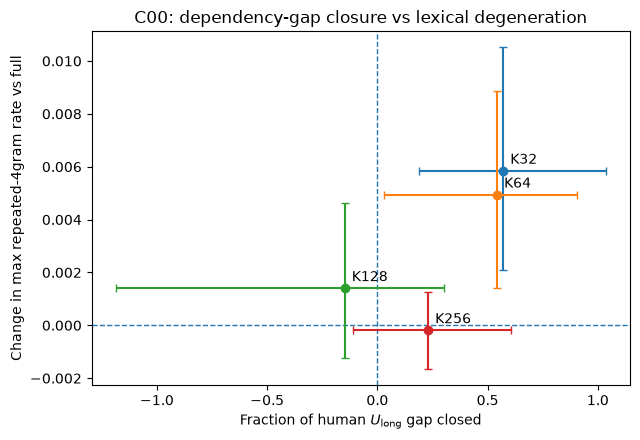

saved: ../results/causal/C00_effective_history_gap_closure/quality_gap_frontier.png


In [32]:
# ============================================================
# Merge objective degeneration with causal gap closure
# ============================================================

closure_frontier = (
    baseline_defined_audit[
        baseline_defined_audit["condition"].isin(
            ["K32", "K64", "K128", "K256"]
        )
    ][
        [
            "condition",
            "history_cap",
            "baseline_n",
            "eligible_n",
            "retention_fraction",
            "closure",
            "closure_ci_low",
            "closure_ci_high",
        ]
    ]
    .copy()
)


def metric_frontier(metric, prefix):
    x = (
        frontier_quality[
            frontier_quality["metric"].eq(metric)
        ][
            [
                "condition",
                "delta_vs_full",
                "ci_low",
                "ci_high",
            ]
        ]
        .rename(columns={
            "delta_vs_full": f"{prefix}_delta",
            "ci_low": f"{prefix}_ci_low",
            "ci_high": f"{prefix}_ci_high",
        })
    )

    return x


frontier = closure_frontier.copy()

frontier = frontier.merge(
    metric_frontier(
        "repeat4_fraction",
        "repeat4",
    ),
    on="condition",
    validate="one_to_one",
)

frontier = frontier.merge(
    metric_frontier(
        "distinct4",
        "distinct4",
    ),
    on="condition",
    validate="one_to_one",
)

frontier = frontier.merge(
    metric_frontier(
        "max_repeat4_rate",
        "maxrep4rate",
    ),
    on="condition",
    validate="one_to_one",
)

frontier = frontier.merge(
    metric_frontier(
        "word_count",
        "words",
    ),
    on="condition",
    validate="one_to_one",
)

frontier = frontier.sort_values(
    "history_cap"
).reset_index(drop=True)

print("=== C00 QUALITY–GAP FRONTIER ===")

display(
    frontier[
        [
            "condition",
            "eligible_n",
            "retention_fraction",

            "closure",
            "closure_ci_low",
            "closure_ci_high",

            "repeat4_delta",
            "repeat4_ci_low",
            "repeat4_ci_high",

            "distinct4_delta",
            "distinct4_ci_low",
            "distinct4_ci_high",

            "maxrep4rate_delta",
            "maxrep4rate_ci_low",
            "maxrep4rate_ci_high",
        ]
    ]
)

frontier.to_csv(
    OUT / "quality_gap_frontier.csv",
    index=False,
)


# ------------------------------------------------------------
# Visual frontier:
#
# x = fraction of U_long human gap closed
# y = change in localized normalized repetition
#
# Ideal region is lower-right:
# lots of gap closure, little/no degeneration.
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

for _, r in frontier.iterrows():

    ax.errorbar(
        r["closure"],
        r["maxrep4rate_delta"],

        xerr=[[
            r["closure"]
            - r["closure_ci_low"]
        ], [
            r["closure_ci_high"]
            - r["closure"]
        ]],

        yerr=[[
            r["maxrep4rate_delta"]
            - r["maxrep4rate_ci_low"]
        ], [
            r["maxrep4rate_ci_high"]
            - r["maxrep4rate_delta"]
        ]],

        marker="o",
        capsize=3,
    )

    ax.annotate(
        r["condition"],
        (
            r["closure"],
            r["maxrep4rate_delta"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )


ax.set_xlabel(
    r"Fraction of human $U_{\rm long}$ gap closed"
)

ax.set_ylabel(
    "Change in max repeated-4gram rate vs full"
)

ax.set_title(
    "C00: dependency-gap closure vs lexical degeneration"
)

fig.tight_layout()

FRONTIER_FIG = (
    OUT
    / "quality_gap_frontier.png"
)

fig.savefig(
    FRONTIER_FIG,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("saved:", FRONTIER_FIG)

In [33]:
# ============================================================
# C00 qualitative inspection:
# representative full-history vs K32 pairs
# ============================================================

from IPython.display import display, HTML
import html

# Exact population underlying the primary K32 causal estimate.
sample_ids = set(k32_eligible_ids)

# ------------------------------------------------------------
# Build per-source K32/full diagnostics
# ------------------------------------------------------------

obj_wide = (
    frontier_obj[
        frontier_obj["source_id"].astype(str).isin(sample_ids)
        & frontier_obj["condition"].isin(["K32", "full"])
    ]
    .pivot(
        index="source_id",
        columns="condition",
        values=[
            "word_count",
            "repeat4_fraction",
            "distinct4",
            "max_repeat4_rate",
        ],
    )
)

rows = []

for sid in obj_wide.index.astype(str):

    a = analysis[
        analysis["source_id"].astype(str).eq(sid)
        & analysis["condition"].isin(["K32", "full"])
    ].set_index("condition")

    rows.append({
        "source_id": sid,

        "full_U_long": a.loc["full", "U_long"],
        "K32_U_long": a.loc["K32", "U_long"],

        "human_U_long": a.loc["full", "human_U_long"],

        # Human-relative gap change.
        # Negative means K32 moved U_long toward human
        # when the original full gap is positive.
        "delta_gap": (
            (a.loc["K32", "U_long"] - a.loc["full", "human_U_long"])
            -
            (a.loc["full", "U_long"] - a.loc["full", "human_U_long"])
        ),

        "full_maxrep4rate": obj_wide.loc[
            sid, ("max_repeat4_rate", "full")
        ],
        "K32_maxrep4rate": obj_wide.loc[
            sid, ("max_repeat4_rate", "K32")
        ],

        "delta_maxrep4rate": (
            obj_wide.loc[sid, ("max_repeat4_rate", "K32")]
            -
            obj_wide.loc[sid, ("max_repeat4_rate", "full")]
        ),

        "full_repeat4": obj_wide.loc[
            sid, ("repeat4_fraction", "full")
        ],
        "K32_repeat4": obj_wide.loc[
            sid, ("repeat4_fraction", "K32")
        ],

        "full_words": obj_wide.loc[
            sid, ("word_count", "full")
        ],
        "K32_words": obj_wide.loc[
            sid, ("word_count", "K32")
        ],
    })

inspection = pd.DataFrame(rows)

# ------------------------------------------------------------
# Pick three qualitatively useful examples
# ------------------------------------------------------------

median_rep = inspection["delta_maxrep4rate"].median()

typical_id = (
    inspection.assign(
        dist_to_median=(
            inspection["delta_maxrep4rate"] - median_rep
        ).abs()
    )
    .sort_values("dist_to_median")
    .iloc[0]["source_id"]
)

largest_rep_id = (
    inspection
    .sort_values("delta_maxrep4rate", ascending=False)
    .iloc[0]["source_id"]
)

smallest_rep_id = (
    inspection
    .sort_values("delta_maxrep4rate")
    .iloc[0]["source_id"]
)

chosen = [
    ("TYPICAL REPETITION SHIFT", typical_id),
    ("LARGEST REPETITION SHIFT", largest_rep_id),
    ("SMALLEST REPETITION SHIFT", smallest_rep_id),
]


def show_pair(label, sid):

    q = qpair[
        qpair["source_id"].astype(str).eq(str(sid))
    ].iloc[0]

    m = inspection[
        inspection["source_id"].astype(str).eq(str(sid))
    ].iloc[0]

    stats = f"""
    <b>{html.escape(label)}</b><br>
    source_id = {html.escape(str(sid))}<br><br>

    <b>U_long:</b>
    human={m.human_U_long:.3f},
    full={m.full_U_long:.3f},
    K32={m.K32_U_long:.3f}<br>

    <b>K32 - full U-gap change:</b>
    {m.delta_gap:+.3f}
    (negative = toward human if full starts above human)<br><br>

    <b>max-repeat4-rate:</b>
    full={m.full_maxrep4rate:.4f},
    K32={m.K32_maxrep4rate:.4f},
    Δ={m.delta_maxrep4rate:+.4f}<br>

    <b>repeat4 fraction:</b>
    full={m.full_repeat4:.3f},
    K32={m.K32_repeat4:.3f}<br>

    <b>word count:</b>
    full={m.full_words:.0f},
    K32={m.K32_words:.0f}
    """

    prompt = html.escape(str(q["prompt"]))
    full = html.escape(str(q["full"]))
    k32 = html.escape(str(q["K32"]))

    display(HTML(f"""
    <div style="
        border:1px solid #aaa;
        padding:14px;
        margin:18px 0;
        border-radius:8px;
    ">

        <div style="margin-bottom:12px;">
            {stats}
        </div>

        <div style="
            background:#f5f5f5;
            padding:10px;
            margin-bottom:14px;
            white-space:pre-wrap;
        ">
            <b>PROMPT</b><br>{prompt}
        </div>

        <div style="
            display:grid;
            grid-template-columns:1fr 1fr;
            gap:16px;
        ">

            <div>
                <h4>FULL HISTORY</h4>
                <div style="
                    white-space:pre-wrap;
                    border:1px solid #ddd;
                    padding:12px;
                ">{full}</div>
            </div>

            <div>
                <h4>K32</h4>
                <div style="
                    white-space:pre-wrap;
                    border:1px solid #ddd;
                    padding:12px;
                ">{k32}</div>
            </div>

        </div>
    </div>
    """))


for label, sid in chosen:
    show_pair(label, sid)


# Interpretation map

## A. Full-history human gap is absent

If `FULL_GAP_PRESENT=False`, C00 does **not** establish human-gap closure. The
history sweep can still reveal a causal dependence of \(U\) on effective
self-history, but there is no resolved baseline gap in this generator/sample to
attribute.

## B. History restriction closes the gap

Strong mechanistic evidence requires convergence of several quantities:

1. finite caps reduce the matched human-relative \(U_{\rm long}\) gap;
2. scalar closure \(C_{K,\rm long}>0\);
3. the three-coordinate shift points toward humans:
   \[
   A_K>0;
   \]
4. projected closure is positive:
   \[
   P_K>0;
   \]
5. residual vector gap shrinks:
   \[
   R_K<1;
   \]
6. the finite-cap dose response has positive mean slope with increasing \(K\).

A strong result supports:

\[
\boxed{
\text{effective autoregressive self-history is one causal contributor to the}
}
\]

\[
\boxed{
\text{human--LLM dependency-organization gap measured by RELIC.}
}
\]

It does **not** imply that history range is the only cause.

## C. \(U\) moves but not toward humans

Then generator self-history causally affects the measurement, but it does not
explain the observed population difference:

\[
\delta_{\rm history}\not\parallel -g_{\rm LLM-human}.
\]

That is a useful mechanistic negative.

## D. Only long-range coordinates close

If \(U_{128}\) and \(U_{256}\) close substantially while \(U_{32}\) does not, that
is especially diagnostic: the intervention reproduces the *shape* expected from a
long-history mechanism rather than merely shifting overall scorer calibration.

## E. Eligibility changes strongly with \(K\)

Stopping behavior is itself affected by the mechanism. If common eligibility
shrinks substantially or common and pairwise sensitivity estimates disagree, the
frozen-384 result must be reported as selected by a post-treatment length criterion.

## Next causal experiments

C00 deliberately targets the already-established \(U\) gap rather than adding a
large feature panel.

If C00 works, subsequent C notebooks should test distinct source mechanisms against
their corresponding observed gaps, for example:

- repetition suppression / lexical reuse dynamics;
- post-training (matched base \(\rightarrow\) instruct checkpoints);
- decoding entropy;
- long-range attention strength with history availability held fixed.

Candidate **new** completed-text measurements should first establish a real
human/LLM or AI/AI difference on an independent observational split before being
added to causal gap-attribution notebooks. This keeps the C-series from becoming
post-hoc feature mining.
